# Cross-sell and upsell reasoning; expected value in rupees: what is a combo worth?

**Week 4, Wednesday, chapter 9, the last chapter of the concept block.** The topic, in the
curriculum's words: *Cross-sell and upsell reasoning; expected value in rupees*. Sharma
Kirana, a corner shop in Pune, is invented for this chapter: every number below is read
from its month in `data/`, and the code only confirms the arithmetic.

**Who needs the answer.** The owner of Sharma Kirana, who is weighing a counter card that
reads "Tea and rusk together, Rs 1 off". Rusk beside tea is **cross-sell**, a second item
that goes with the first; the bigger tea pack in place of the small one would be
**upsell**, a dearer version of the same item.

**The questions on the way.** Cross-sell or upsell? Which bills can the card change? What
is it worth in a month? What decides the sign?

In [1]:
def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)
    assert ok, name
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})
import pandas as pd

kirana = pd.read_csv("../data/C2_W04_D03_kirana_month_STUDENT.csv")
k = kirana.set_index("line").value
print("Sharma Kirana's month, invented:")
for line, value, what in kirana.itertuples(index=False):
    print(f"  {line}: {value:g}  ({what})")
n, tea, rusk, both = (int(k[x]) for x in ["bills", "bills_with_tea", "bills_with_rusk", "bills_with_both"])
lift = both / (n * (tea / n) * (rusk / n))
print(f"tea and rusk: support {both / n:.2f}, lift {lift:.2f}, chapter 3's count")
check("tea and rusk meet a little more often than chance: lift 1.25, under the 1.5 bar", round(lift, 2) == 1.25)

Sharma Kirana's month, invented:
  bills: 1000  (bills rung up in the month)
  bills_with_tea: 600  (bills holding a tea pack)
  bills_with_rusk: 200  (bills holding a rusk pack)
  bills_with_both: 150  (bills holding both)
  rusk_price_rs: 30  (what a rusk pack sells for)
  rusk_cost_rs: 18  (what a rusk pack costs the shop)
  combo_discount_rs: 1  (taken off every bill that holds tea and rusk once the card is up)
  card_printing_rs: 20  (printing the combo cards for the month)
  response_low: 0.02  (assumption, low end: share of tea bills without rusk that add a pack)
  response_mid: 0.04  (assumption, middle: the same share)
  response_high: 0.06  (assumption, high end: the same share)
tea and rusk: support 0.15, lift 1.25, chapter 3's count
PASS tea and rusk meet a little more often than chance: lift 1.25, under the 1.5 bar


## What is the tea-and-rusk card worth in a month?

Tea and rusk meet a little more often than chance on plenty of bills, lift 1.25, under
chapter 6's 1.5 bar: a weak pull that would earn no slot of its own. A card is the shop's
cheapest bet on it, and the question is what that bet is worth. The card gives Rs 1 back
on every bill holding both, and the owner assumes 4 percent of the tea bills without rusk
will add a pack, somewhere between 2 and 6 percent; the card is assumed to change no
other bill.

**Predict before you run.** Which number should the owner weigh against the card?

a) Rs 5,040, the rusk sold on every bill that will hold both.
b) Rs 2,016, the rusk margin on every bill that will hold both.
c) Rs 196, the margin on the new packs less the printing.
d) Rs 28, the margin on the new packs less every rupee the card costs.

In [2]:
price, cost, off, printing = k["rusk_price_rs"], k["rusk_cost_rs"], k["combo_discount_rs"], k["card_printing_rs"]
margin = price - cost                        # what the shop keeps from a pack
tea_only = tea - both                        # the only bills the card can change
new = round(tea_only * k["response_mid"])    # packs added at the assumed 4 percent
combos = both + new                          # every bill that will hold both, old and new
value = new * margin - combos * off - printing
print(f"tea bills without rusk: {tea_only}; new packs at 4 percent: {new}; margin a pack: Rs {margin:g}")
print(f"Rs {new * margin:g} of new margin, less Rs {combos * off:g} on {combos} combo bills, "
      f"less Rs {printing:g} of printing: Rs {value:g} a month")
check("the card is worth Rs 28 a month", value == 28)
check("the discount is paid on 168 bills, the 18 new ones among them", combos == 168 and new == 18)

tea bills without rusk: 450; new packs at 4 percent: 18; margin a pack: Rs 12
Rs 216 of new margin, less Rs 168 on 168 combo bills, less Rs 20 of printing: Rs 28 a month
PASS the card is worth Rs 28 a month
PASS the discount is paid on 168 bills, the 18 new ones among them


**What happened.** The answer is d. The card is assumed to change only the
450 tea bills without rusk, and 18 of them add a pack worth
Rs 12 of margin: Rs 216. The card hands
Rs 1 back on all 168 bills that hold both, the
150 that held both anyway among them, and the cards cost
Rs 20, which leaves Rs 28. **The trap, exactly:**
Rs 5,040, rusk sales on every combo bill, which prints a card as if it
earned 180 times what it does. **The check** is "which bills does
the card change?"; **the fix** is margin on those bills only, less what the card gives
away. The bridge below builds the number one bar at a time.

rusk sales on every combo bill: Rs 5,040
rusk margin on every combo bill: Rs 2,016
the discount forgotten: Rs 196
the sales figure is 180 times the gain


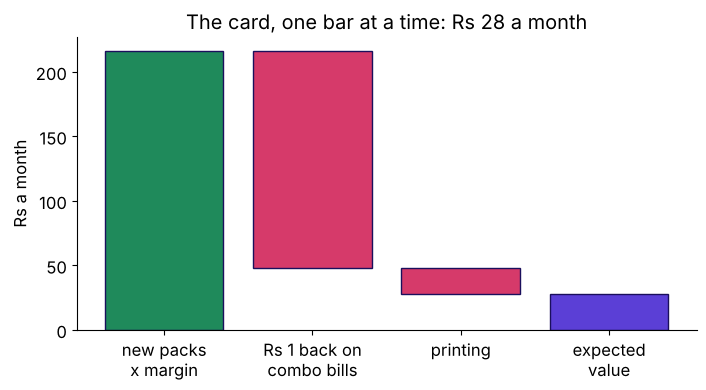

PASS rusk sales overstate the gain 180 times


In [3]:
wrong = {"rusk sales on every combo bill": combos * price,
         "rusk margin on every combo bill": combos * margin,
         "the discount forgotten": new * margin - printing}
for name, x in wrong.items():
    print(f"{name}: Rs {x:,.0f}")
print(f"the sales figure is {combos * price / value:.0f} times the gain")
steps = [("new packs\nx margin", new * margin), ("Rs 1 back on\ncombo bills", -combos * off),
         ("printing", -printing)]
fig, ax = plt.subplots(figsize=(8, 3.8))
run = 0
for i, (label, x) in enumerate(steps):
    ax.bar(i, abs(x), bottom=run if x > 0 else run + x, color="#1F8A5B" if x > 0 else "#D63A6A", edgecolor="#1A0F5C")
    run += x
ax.bar(len(steps), run, color="#5B3FD6", edgecolor="#1A0F5C")
ax.set_xticks(range(len(steps) + 1), [s for s, _ in steps] + ["expected\nvalue"])
ax.set_ylabel("Rs a month")
ax.set_title("The card, one bar at a time: Rs 28 a month")
plt.show()
check("rusk sales overstate the gain 180 times", combos * price / value == 180)

## How does expected value weigh each bill?

The rule, named last: **expected value** is each outcome times its probability, added up,
a weighted average (Wikipedia's expected value page, checked 13 October 2026). One tea bill
without rusk earns Rs 11, a pack's margin less the rupee its bill
takes back, with probability 4 percent, and nothing on the other
0.96: Rs 0.44 a bill. A second route checks it
without probabilities: the shop's rusk margin with the card against the same month
without it.

one tea-only bill: 0.04 x Rs 11, and nothing on the other 0.96: Rs 0.44
450 bills: Rs 198; less Rs 150 on the bills that held both and Rs 20 of printing: Rs 28
with and without: Rs 2,428 of rusk margin with the card, Rs 2,400 without: Rs 28


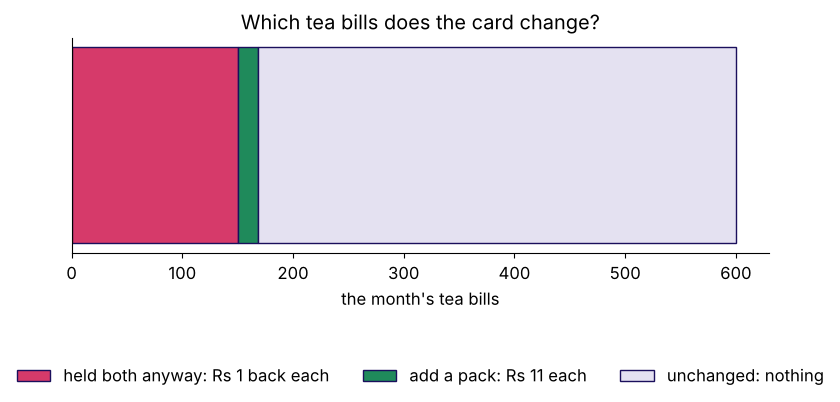

PASS the weighted average and the with-and-without route give Rs 28


In [4]:
p = k["response_mid"]
per_bill = p * (margin - off)                     # one tea-only bill; the other 0.96 earn nothing
route_two = tea_only * per_bill - both * off - printing
before = rusk * margin
after = (rusk + new) * margin - combos * off - printing
print(f"one tea-only bill: {p:.2f} x Rs {margin - off:g}, and nothing on the other {1 - p:.2f}: Rs {per_bill:.2f}")
print(f"{tea_only} bills: Rs {tea_only * per_bill:.0f}; less Rs {both * off:g} on the bills that held both "
      f"and Rs {printing:g} of printing: Rs {route_two:.0f}")
print(f"with and without: Rs {after:,.0f} of rusk margin with the card, Rs {before:,.0f} without: Rs {after - before:,.0f}")
fig, ax = plt.subplots(figsize=(9, 2.8))
parts = [(both, "#D63A6A", "held both anyway: Rs 1 back each"),
         (new, "#1F8A5B", "add a pack: Rs 11 each"),
         (tea_only - new, "#E4E1F1", "unchanged: nothing")]
left = 0
for width, colour, label in parts:
    ax.barh(0, width, left=left, color=colour, edgecolor="#1A0F5C", label=label)
    left += width
ax.set_yticks([])
ax.set_xlabel("the month's tea bills")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.45))
ax.set_title("Which tea bills does the card change?")
plt.show()
check("the weighted average and the with-and-without route give Rs 28",
      round(route_two) == value == after - before)

## What decides the sign?

Two numbers the owner sets or guesses move the answer. Every extra rupee off costs
Rs 168 a month, since it is paid on every combo bill, so at the
same 4 percent response the card earns nothing at about Rs 1.17 off; a
bigger discount may draw more buyers, which only a trial of the card would show. And the 4 percent is an assumption:
at 2 percent the card loses money, at 6 percent
it earns more. An assumed response is said with its range, and the answer travels with it.

response 4%, Rs 1 off: Rs 28
response 4%, Rs 2 off: -Rs 140
response 2%, Rs 1 off: -Rs 71
response 6%, Rs 1 off: Rs 127
at a 4 percent response the card earns nothing at Rs 1.17 off


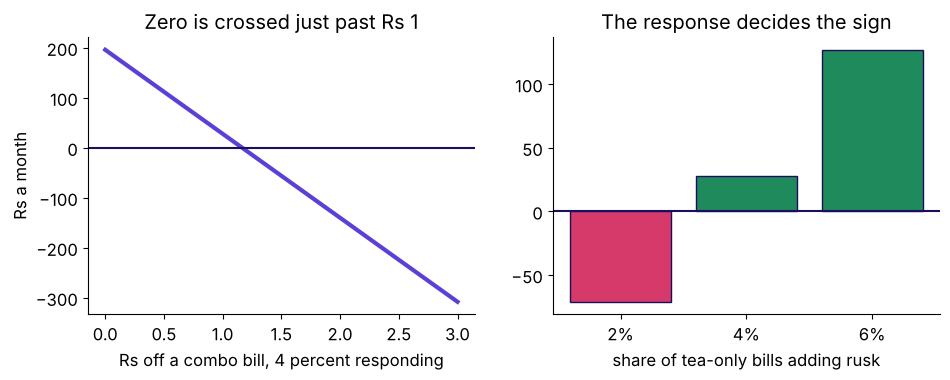

PASS Rs 2 off loses Rs 140
PASS the sign turns on the response: 2 percent loses, 6 percent earns


In [5]:
def card_value(response, off):
    new = round(tea_only * response)
    return new * margin - (both + new) * off - printing


def rs(x):
    return f"{'-' if x < 0 else ''}Rs {abs(x):,.0f}"


for response, off_ in [(0.04, 1), (0.04, 2), (0.02, 1), (0.06, 1)]:
    print(f"response {response:.0%}, Rs {off_} off: {rs(card_value(response, off_))}")
breakeven = (new * margin - printing) / combos
print(f"at a 4 percent response the card earns nothing at Rs {breakeven:.2f} off")
offs = [x / 10 for x in range(0, 31)]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
a1.plot(offs, [card_value(0.04, o) for o in offs], color="#5B3FD6", lw=3)
a1.axhline(0, color="#1A0F5C")
a1.set_xlabel("Rs off a combo bill, 4 percent responding")
a1.set_ylabel("Rs a month")
a1.set_title("Zero is crossed just past Rs 1")
rates = [0.02, 0.04, 0.06]
vals = [card_value(r, 1) for r in rates]
a2.bar([f"{r:.0%}" for r in rates], vals, color=["#D63A6A" if x < 0 else "#1F8A5B" for x in vals], edgecolor="#1A0F5C")
a2.axhline(0, color="#1A0F5C")
a2.set_xlabel("share of tea-only bills adding rusk")
a2.set_title("The response decides the sign")
plt.show()
check("Rs 2 off loses Rs 140", card_value(0.04, 2) == -140)
check("the sign turns on the response: 2 percent loses, 6 percent earns", card_value(0.02, 1) < 0 < card_value(0.06, 1))

### Your turn: what is a bigger shop's card worth?

A card reaches 2,000 bills, 5 percent of them add one extra pack at Rs 10 of margin, and
the cards cost Rs 600. Nothing is handed back on any bill. In the empty cell below,
compute the card's value for the month and store it as `big_card`. Then run the check
under it.

In [6]:
mine = globals().get("big_card")
if mine is None:
    print("Store your answer as big_card in the empty cell above, then run this cell again.")
else:
    reference = round(2000 * 0.05) * 10 - 600
    print(f"reference: Rs {reference:,}; yours: Rs {mine:,.0f}")
    print("matches" if abs(mine - reference) < 0.5 else "not yet: new packs x margin, less the cost")

Store your answer as big_card in the empty cell above, then run this cell again.


## What should you keep from chapter 9?

- Cross-sell suggests a second item that goes with the first; upsell suggests a dearer
  version of the same item, and it is priced the same way: the extra margin of the bigger
  pack on the shoppers who switch, less what the switch gives away.
- A card earns only on the bills it changes, so its gain is margin on the new packs, never
  sales on every combo bill: Rs 28, against Rs 5,040.
- A discount is paid on every bill that takes it, including the bills that would have held
  both anyway.
- Expected value weighs each outcome by its probability, so an assumed response comes with
  its range, and so does the answer: -Rs 71 at
  2 percent and Rs 127 at
  6 percent.

**In the interview.** "A combo offer lifts the pair's sales; is it worth running?" Margin
on the purchases the offer creates, less the discount paid on every purchase that takes
it, including those that would have happened anyway, less the fixed cost, said as a
range. Chapter 10 prices one of Instamart's strip slots the same
way, and the lab prices Kalpa's charger bundle.